In [2]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

filename = r"exoplanets_slim_2026-11-3.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
print(df.dtypes)

(6451, 23)
pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object


In [ ]:
import numpy as np
import pandas as pd


features = ["pl_radius_e", "st_mass", "st_temp", "st_radius", "sys_dist_e", "sys_num_planet", "disc_year"]

d = df.dropna(subset=features + ["pl_orb_period", "disc_method"]).copy()
d = d[d["pl_orb_period"] > 0]
d["log_period"] = np.log10(d["pl_orb_period"])

x = pd.get_dummies(d[features + ["disc_method"]], columns=["disc_method"])
y = d["log_period"]

print(len(df), "->", len(d))

6451 -> 5994


In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

xTrain, xTest, yTrain, yTest = train_test_split(
    x, y, test_size=0.2, random_state=42
)

tree = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42)
tree.fit(xTrain, yTrain)
pred = tree.predict(xTest)

baseline = np.full(len(yTest), yTrain.mean())
print("baseline RMSE:", np.sqrt(mean_squared_error(yTest, baseline)))
print("tree RMSE:", np.sqrt(mean_squared_error(yTest, pred)))
print("tree test R2:", r2_score(yTest, pred))

cv = cross_val_score(tree, xTrain, yTrain, cv=5, scoring="r2")
print("CV R2:", cv.mean().round(3), "+/-", cv.std().round(3))

baseline RMSE: 0.918644906236069
tree RMSE: 0.5346744084209072
tree test R2: 0.6611722920178056
CV R2: 0.623 +/- 0.009


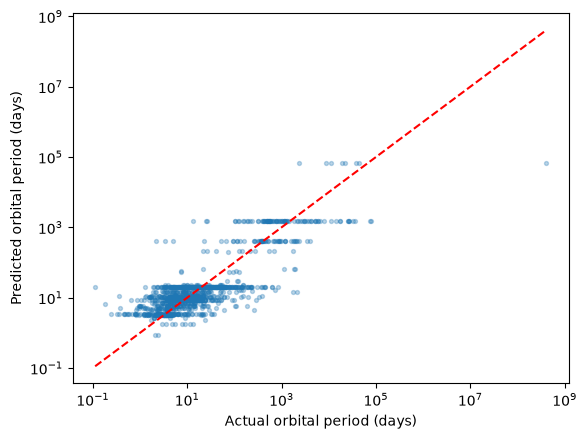

In [10]:
plt.scatter(10 ** yTest, 10 ** pred, s=8, alpha=0.3)
lims = [10 ** yTest.min(), 10 ** yTest.max()]
plt.plot(lims, lims, "r--")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Actual orbital period (days)")
plt.ylabel("Predicted orbital period (days)")
plt.show()

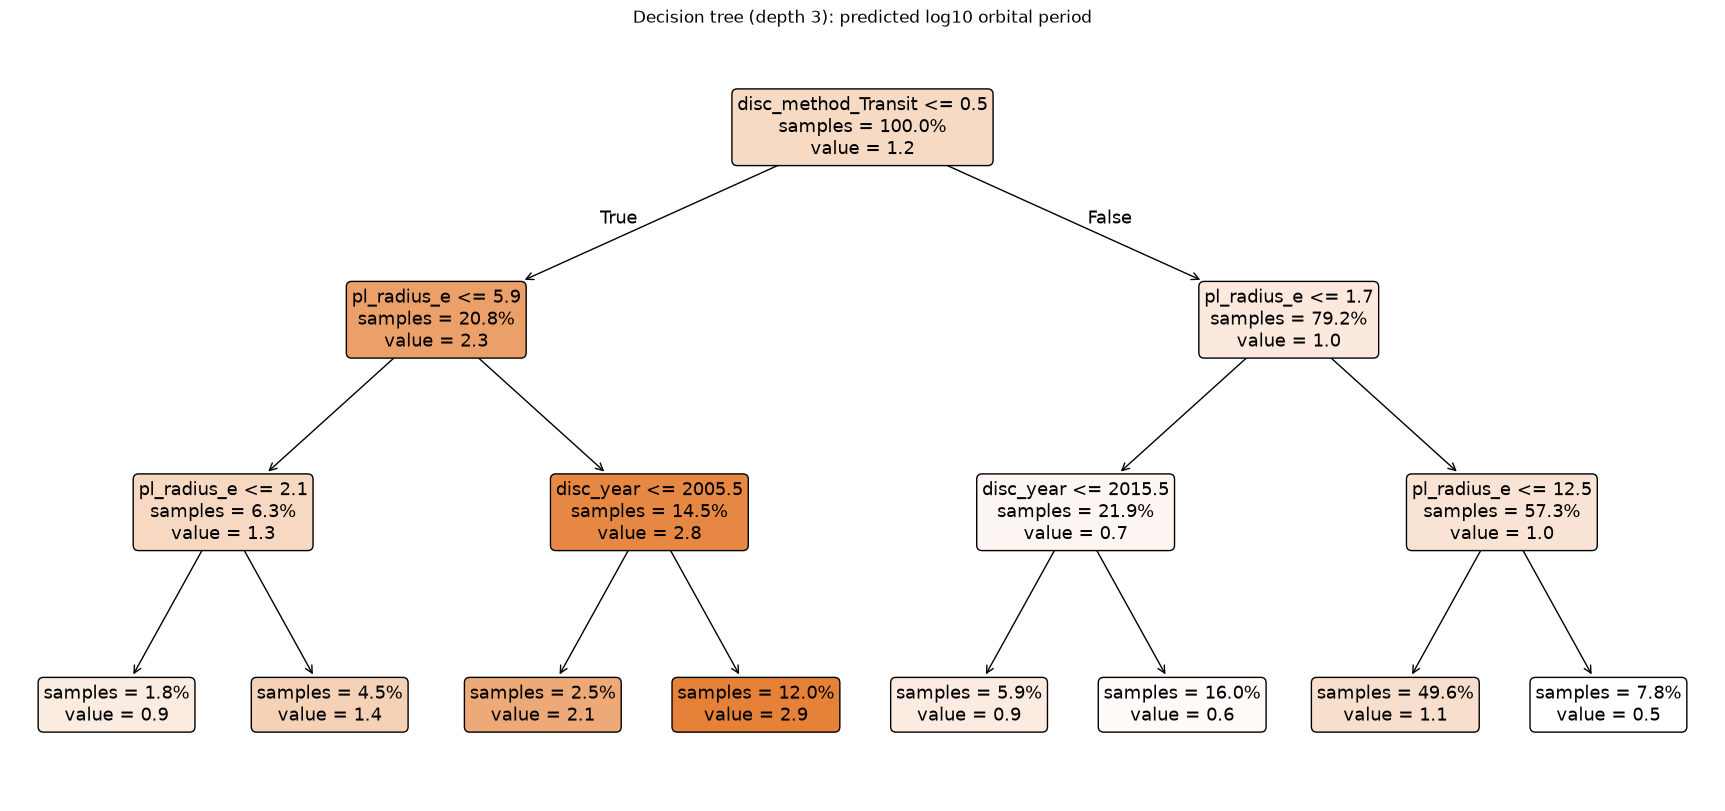

In [ ]:
from sklearn.tree import plot_tree

small = DecisionTreeRegressor(max_depth=3, min_samples_leaf=30, random_state=42)
small.fit(xTrain, yTrain)

plt.figure(figsize=(22, 10))
plot_tree(
    small,
    feature_names=list(x.columns),
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=13,
    precision=1,
)
plt.title("Decision tree (depth 3): predicted log10 orbital period")
plt.show()

In [12]:
from sklearn.tree import export_text
print(export_text(small, feature_names=list(x.columns), decimals=1))

|--- disc_method_Transit <= 0.5
|   |--- pl_radius_e <= 5.9
|   |   |--- pl_radius_e <= 2.1
|   |   |   |--- value: [0.9]
|   |   |--- pl_radius_e >  2.1
|   |   |   |--- value: [1.4]
|   |--- pl_radius_e >  5.9
|   |   |--- disc_year <= 2005.5
|   |   |   |--- value: [2.1]
|   |   |--- disc_year >  2005.5
|   |   |   |--- value: [2.9]
|--- disc_method_Transit >  0.5
|   |--- pl_radius_e <= 1.7
|   |   |--- disc_year <= 2015.5
|   |   |   |--- value: [0.9]
|   |   |--- disc_year >  2015.5
|   |   |   |--- value: [0.6]
|   |--- pl_radius_e >  1.7
|   |   |--- pl_radius_e <= 12.5
|   |   |   |--- value: [1.1]
|   |   |--- pl_radius_e >  12.5
|   |   |   |--- value: [0.5]

